# 01 Data overview

**The question.** Before we price anything, do we have enough trustworthy history? How many past bids, from which years and places, and how well do they hold up when checked?

**What we did.** We collected every bid price for the 100 biggest bid items (by dollars) on Caltrans contracts in **Districts 4 and 5** (the Bay Area and the Central Coast), bid from **2018 to 2026**. The prices come from Caltrans' public cost database. For contract-level facts (the engineer's estimate, working days and the total of every bid), we read Caltrans' bid summary PDFs. We then checked the two sources against each other and ran data quality checks.

**What we found.**
- **72,113 bid prices** across **848 contract openings**, covering every year from 2018 to 2026 in both districts.
- **672 contracts** have a usable bid summary. The gaps are almost all from 2018, which Caltrans no longer posts.
- Where both sources show the low bidder's price, they agree **to the cent 98.6% of the time**. Every difference sits in 11 contracts where the sources name a different low bidder, most likely because a low bid was later rejected.
- Only **1.1% of prices** look unusual by our outlier rule. They are flagged, not deleted.
- Prices for the same item swing a lot from job to job and year to year. That is why the next notebook adjusts prices for inflation before any modeling.

No bidder is named anywhere in this notebook. Bids are identified only by their rank (1 = low bidder).

## Setup

This loads the project's own code (`src/bidlens/analysis/overview.py`) and opens the database built by `make data`. Nothing here changes the data.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)  # run from the project root

import matplotlib.pyplot as plt
from bidlens.analysis import overview as o

con = o.connect()
plt.rcParams["figure.max_open_warning"] = 0

## What we have, in one table

These are the headline counts. A *bid price* is one bidder's price for one item on one contract. A *contract opening* is one day when bids were opened. A contract that was advertised twice counts twice.

In [2]:
headline = o.headline(con)
headline

,Measure,Value
0,Bid prices,72113
1,Bid items (priced lines),14859
2,Contract openings,848
3,Contracts with a bid summary,672
4,Item codes in scope,100
5,First bid date,2018-01-10
6,Last bid date,2026-11-03


## Contracts per year and district

Each bar is the number of contracts bid that year. A steady flow matters because the pricing models learn from older bids and are tested on newer ones. A thin year would leave them little to learn from. Both districts have contracts in every year. 2026 is lower only because the year is not over (data runs to November 3).

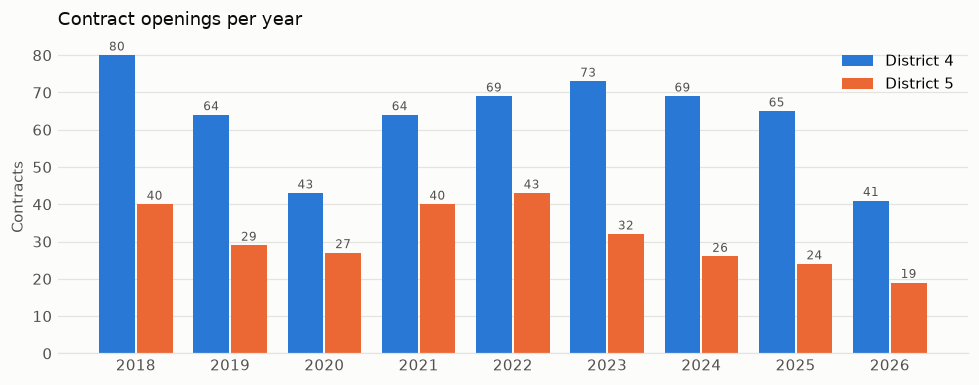

In [3]:
by_year = o.contracts_by_year(con)
fig = o.chart_contracts_by_year(by_year)
o.save(fig, "contracts_by_year")
plt.show()

## Which contracts have a bid summary

The bid summary is the one-page Caltrans record of every bid total and the engineer's estimate. We need it for the market questions (how far bids land from the estimate, and how many bidders show up). From 2019 on, nearly every contract has one. Caltrans no longer posts 2018 summaries, so 2018 can be used for item prices but not for those contract-level questions.

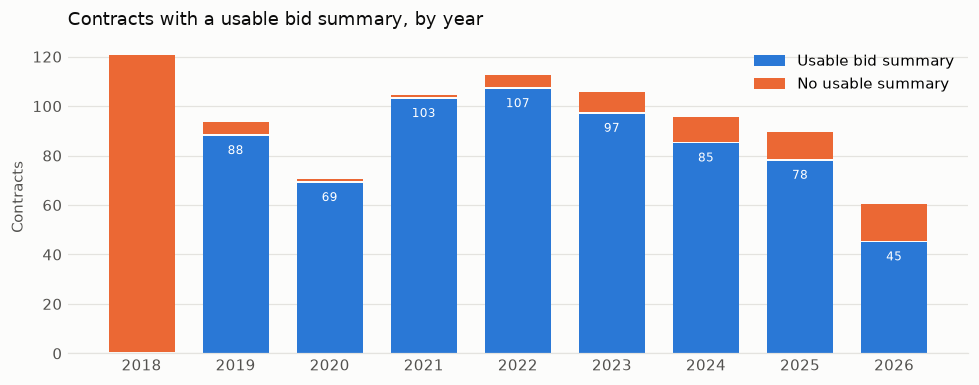

,year,Usable bid summary,No usable summary
0,2018,0,120
1,2019,88,5
2,2020,69,1
3,2021,103,1
4,2022,107,5
5,2023,97,8
6,2024,85,10
7,2025,78,11
8,2026,45,15


In [4]:
coverage = o.summary_coverage_by_year(con)
fig = o.chart_summary_coverage(coverage)
o.save(fig, "bid_summary_coverage")
plt.show()
coverage

## Where the money is: item families

We group the 100 items into families that estimators recognize, using Caltrans' own specification sections. The chart shows the total of all low bids in each family. Mobilization and overhead, asphalt paving and traffic control carry the most dollars. Those are the families where accurate pricing matters most.

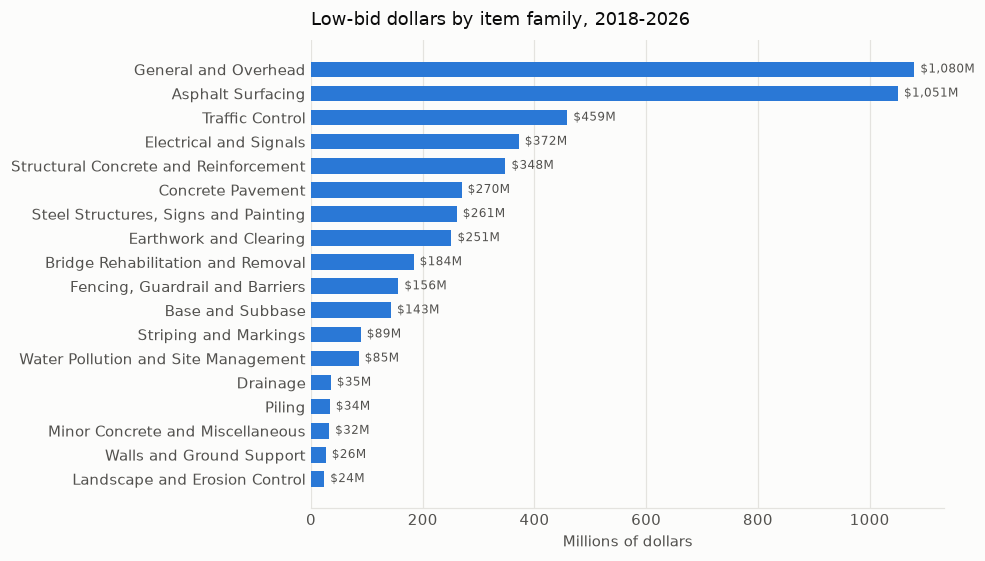

In [5]:
fam = o.families(con)
fig = o.chart_families(fam)
o.save(fig, "low_bid_dollars_by_family")
plt.show()

## Do the two Caltrans sources agree?

The same low-bid prices appear both in the cost database and in the bid summary PDFs, so we compared them one by one: 11,947 prices. Each dot below is one price. Dots on the dashed line are identical in both sources. Almost all of them fall on the line. The orange dots all come from 11 contracts where the two sources name a different low bidder. That points to a ranking change, not to bad numbers, and those contracts are flagged.

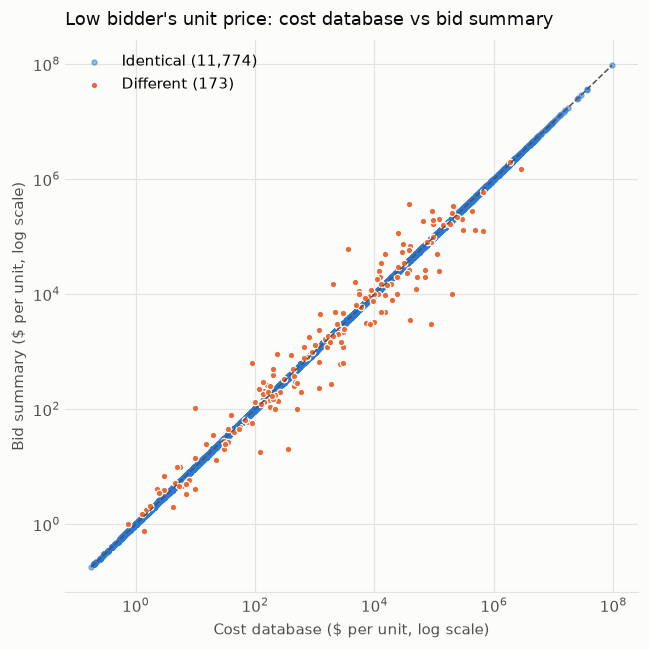

,Result,Prices,Share
0,Identical to the cent,11774,98.6%
1,Differs: sources name a different low bidder,173,1.4%
2,Differs on one item only,0,0.0%


In [6]:
xc = o.cross_check()
fig = o.chart_cross_check(xc)
o.save(fig, "cross_check")
plt.show()
cross = o.cross_check_table(xc)
cross

## Data quality checks

We checked every price and contract for missing values, zero or negative prices, duplicates, totals that don't add up, and unusual prices. A price is flagged as unusual when it sits far from the typical price for the same item, measured on a scale that handles very cheap and very expensive items alike (decision D-033). Flagged data is kept and marked, not deleted, so it stays traceable. The one zero price is a real $0 mobilization bid.

In [7]:
quality = o.quality(con)
quality

,Applies to,Check,Flagged
0,Bid price,price_outlier,773
1,Bid price,non_positive_price,1
2,Contract,low_bidder_disagrees,11
3,Contract,bidder_count_mismatch,8
4,Contract,missing_engineers_estimate,176


## Why prices need adjusting: one item over time

Hot mix asphalt (Type A) is one of the most common items. Each dot is the low bid on one contract, and the orange line is the median for each year. Two things stand out. Prices on a single job can be several times higher or lower than typical, often because of job size. And the typical price moves from year to year, roughly $155 to $260 a ton. To compare a 2019 bid with a 2026 one fairly, we first bring old prices into today's dollars. That is the job of the next notebook, *02 Price escalation*.

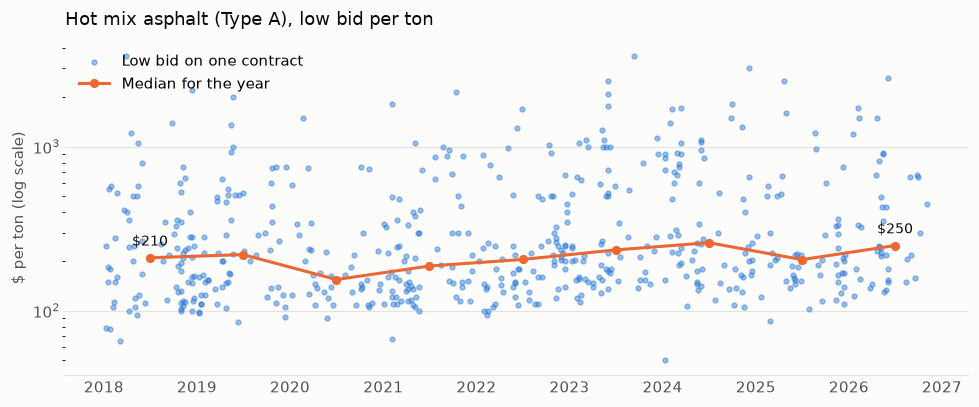

In [8]:
hma = o.hma_prices(con)
fig = o.chart_hma(hma)
o.save(fig, "hma_type_a_prices")
plt.show()

## Save the results

This writes the tables and charts above to `outputs/07_data_overview/`, with a README, so they can be checked without running the notebook.

In [9]:
saved = o.save_tables({
    "headline": headline,
    "contracts_by_year": by_year,
    "bid_summary_coverage_by_year": coverage,
    "item_families": fam,
    "cross_check_summary": cross,
    "data_quality_summary": quality,
})
o.write_readme()
sorted(p.name for p in o.OUT.iterdir())

['README.md',
 'bid_summary_coverage.png',
 'bid_summary_coverage_by_year.csv',
 'contracts_by_year.csv',
 'contracts_by_year.png',
 'cross_check.png',
 'cross_check_summary.csv',
 'data_quality_summary.csv',
 'headline.csv',
 'hma_type_a_prices.png',
 'item_families.csv',
 'low_bid_dollars_by_family.png']

## Where to look next

- **Every number in detail:** [`outputs/`](../outputs/README.md), stages 01 to 06.
- **Next notebook:** *02 Price escalation*, which brings historical prices to today's dollars with the Caltrans Construction Cost Index.